# Day20 matplotlib으로 시간과 거리 그리기

## 선택 학습 시작

타이머를 쓰려면 바로 아래 시작 셀을 먼저 실행해요. 다시 실행해도 이전 시작 기록을 유지해요.
타이머를 쓰지 않으면 이 셀을 건너뛰고 학습해도 돼요.


In [ ]:
# 이 셀은 커널을 다시 시작한 뒤에도 독립적으로 작동해요.
from pathlib import Path

_cwd = Path.cwd()
_dirs = [
    p
    for p in (_cwd, _cwd / "day20-matplotlib-time-distance")
    if p.name == "day20-matplotlib-time-distance"
    and p.is_dir()
    and (p / "day20.ipynb").is_file()
    and (p / "study_timer.py").is_file()
]
if (
    len(_dirs) != 1
    or _dirs[0].is_symlink()
    or (_dirs[0] / "day20.ipynb").is_symlink()
    or (_dirs[0] / "study_timer.py").is_symlink()
):
    print("교재 폴더를 하나로 확인할 수 없어요. Day20 폴더에서 노트북을 열어 주세요.")
else:
    # 검증한 파일을 메모리에서 읽고 실행해요. 임포트 캐시는 만들지 않아요.
    _helper = _dirs[0] / "study_timer.py"
    _timer = {"__name__": "day20_timer"}
    try:
        exec(compile(_helper.read_bytes(), str(_helper), "exec"), _timer)
    except (OSError, SyntaxError):
        print("타이머 도구를 읽을 수 없어요. 기록을 바꾸지 않고 함께 확인해 주세요.")
    else:
        _timer["action"]("start")

## 오늘의 학습

2026-11-08 · 필수 약 60분 · 가상 로봇 시뮬레이션

오늘은 **matplotlib 사용법을 지금 배우고**, 시간과 거리 그래프를 직접 만들어요.
Day19의 시간 짝짓기와 함수는 잠깐만 확인하고, 필요한 기존 함수는 이 노트북 안에서 제공해요.
다른 노트북에서 복사할 필요가 없어요. 여기의 숫자는 실제 센서 측정값이 아니에요.

**학습 순서**

① 맨 위 시작 셀 실행 → ② 문제 풀기 → ③ 맨 아래 종료 셀 실행 후 `종료` 입력 → ④ Ctrl+S로 노트북 저장 → ⑤ 이 대화에 `다 풀었어`라고 알려주기

타이머는 선택이에요. 타이머를 쓰는 경우 위 다섯 단계를 따르고, 쓰지 않으면 시작·종료 단계만 건너뛰어요.

1. 타이머를 쓰면 맨 위 시작 셀을 실행해요.
2. 위에서 아래로 설명을 보고 필수 Q1~Q8을 풀어요.
3. 타이머를 썼다면 맨 아래 종료 셀을 실행하고 `종료`를 입력해요.
4. Ctrl+S로 노트북을 저장해요.
5. 이 대화에 `다 풀었어`라고 알려줘요.

종료 시각은 **종료 셀에서 확인한 시각**이에요. 실제 저장 시각이나 채팅을 보낸 시각과는 달라요.
타이머에는 쉬거나 노트북을 닫은 시간도 포함돼요. `모두 실행` 중에는 `종료`를 입력하지 마세요.

**예상 시간**

- 시작 확인 Q1: 3분
- matplotlib 배우기와 Q2: 12분
- 내 그리기 함수 Q3: 10분
- 기존 함수 확인과 같은 시각 비교 Q4: 11분
- 확인 간격 바꾸기 Q5: 8분
- 디버깅 Q6: 6분
- 그래프 설명 Q7: 5분
- 결과 저장과 제출 Q8: 5분

합계 약 60분이며 개인차가 있어요. 선택 활동은 이 시간에 포함하지 않아요.
코드 셀은 Shift+Enter로 실행해요. Markdown 답안 셀은 두 번 누르거나 Enter로 열어 쓰고 Shift+Enter로 마쳐요.
`...`는 **그대로 실행하는 코드가 아니라 채울 자리**예요. 빈칸을 채운 뒤 실행해요.
현재 학습용 Python 환경에는 matplotlib이 확인되어 있어요. 설치 작업은 필요 없어요.


## 시작 확인

시간과 거리를 한 점으로 나타내는 그림이에요. 아래 그림은 **설명용 예시**이며 Q1의 답이 아니에요.

![시간과 거리 평면의 원점 O, 양의 방향, P Q R과 시간 순서](assets/01-time-distance-plane.png)

- 가로축 **x**: 시간(초). 오른쪽으로 갈수록 나중 시각이에요.
- 세로축 **y**: 벽까지 남은 거리(m). 위로 갈수록 더 멀어요.
- 원점 **O(0, 0)**: 시간이 0초이고 거리가 0m인 좌표예요. 로봇의 시작점과 항상 같지는 않아요.
- 예시 P `(0초, 1.4m)` → Q `(1초, 1.0m)` → R `(2초, 0.6m)`는 기록 순서예요.
- **화살표는 그래프에서 읽는 시간 순서**예요. 로봇이 실제 공간에서 저 모양으로 움직였다는 뜻이 아니에요.

### 확인 문제 Q1 짧게 짝짓기 · 필수

**입력 자료:** 두 로봇이 모두 2.0초에 이동을 시작했어요.

- A: 0.5초 이동한 **후** 벽까지 0.9m가 남았어요.
- B: 1.0초 이동한 **후** 벽까지 0.6m가 남았어요.

**할 일:** 이동 **후 시각과 그때 거리**를 각각 적고, 두 점이 같은 시각인지 판단해요.

**답할 곳:** 바로 아래 `Q1 답안` Markdown 셀. 코드는 수정하지 않아요.


**Q1 답안**

- A의 이동 후 점: (2.5초, 0.9m)
- B의 이동 후 점: (3.0초, 0.6m)
- 같은 시각인가요? 아니


## matplotlib 배우기

### 도구를 불러와 점을 그려요

`import matplotlib.pyplot as plt`는 그래프 도구를 불러오고 짧은 이름 `plt`로 쓰겠다는 뜻이에요.
`fig, ax = plt.subplots()`는 **새 그림 전체 fig**와 **그 안에서 그릴 영역 ax**를 만들어요.
종이 전체가 `fig`, 그 종이에 그린 그래프 칸이 `ax`라고 생각하면 돼요.

`ax.plot(시간_목록, 거리_목록)`은 같은 순서의 두 값을 한 점으로 묶고 점들을 선으로 이어요.
시간을 먼저, 거리를 다음에 넣어요. 두 목록의 길이는 같아야 해요.
점 사이의 선은 입력한 기록을 연결한 그림이에요. 선을 그렸다고 그 사이의 측정값이 추가되는 것은 아니에요.
`marker='o'`는 실제로 목록에 있는 점에 동그라미를 표시해요.
`plt.show()`는 완성한 그림을 화면에 보여줘요.

**제공 예제 A:** 바로 아래 코드 셀은 수정하지 말고 실행만 해요.
0초의 1.6m, 0.5초의 1.3m, 1.0초의 1.0m가 짝이에요.


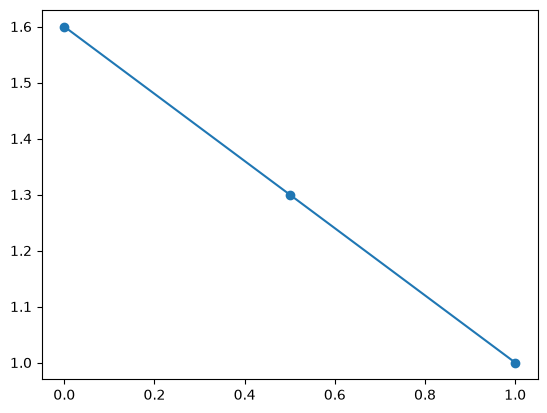

In [ ]:
import matplotlib.pyplot as plt  # 그래프 도구를 plt라는 짧은 이름으로 불러와요

example_times_s = [0.0, 0.5, 1.0]  # 예시 시각 목록, 단위는 초
example_distances_m = [1.6, 1.3, 1.0]  # 같은 순서로 기록한 벽까지 거리, 단위는 m
fig, ax = plt.subplots()  # 새 그림 전체 fig와 그릴 영역 ax
ax.plot(example_times_s, example_distances_m, marker="o")
plt.show()  # 지금 만든 그림을 보여줘요

### 이름과 단위를 붙여 읽기 쉽게 만들어요

![fig 전체와 ax 영역, 제목, 시간과 거리 축 이름, 점, 눈금선과 범례](assets/02-plot-anatomy.png)

- `ax.set_xlabel('Time (s)')`: 가로축에 시간과 초 단위를 적어요.
- `ax.set_ylabel('Distance (m)')`: 세로축에 벽까지 거리와 m 단위를 적어요.
- `ax.set_title('Demo time-distance')`: 그림 위에 제목을 붙여요.
- `ax.grid(True)`: 값을 읽기 쉽도록 눈금선을 켜요.
- `label='demo'`: 선의 이름을 정해요.
- `ax.legend()`: 그 이름을 **범례**, 즉 선 이름표에 보여줘요. label만 적으면 이름표가 나타나지 않아요.

**제공 예제 B:** 바로 아래 셀은 수정하지 말고 실행만 해요.
예제 A의 그림에 덧칠하지 않고 `plt.subplots()`로 **별도의 새 그림**을 만들어요.
영어 제목과 축 이름은 한글 글꼴이 없는 환경에서도 읽을 수 있게 사용해요.


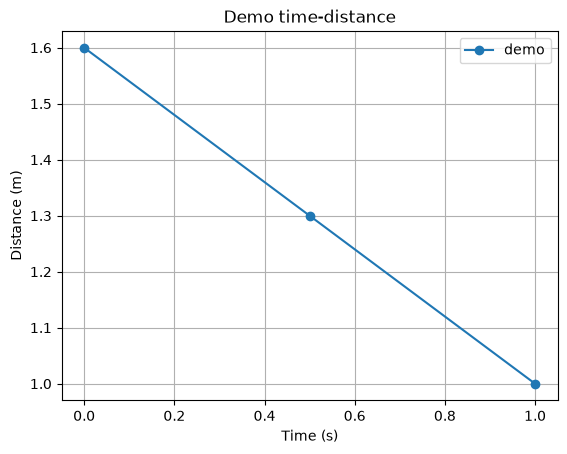

In [ ]:
fig, ax = plt.subplots()  # 예제 A와 별개인 새 그림
ax.plot(example_times_s, example_distances_m, marker="o", label="demo")
ax.set_xlabel("Time (s)")  # x축: 시간, 초
ax.set_ylabel("Distance (m)")  # y축: 벽까지 남은 거리, m
ax.set_title("Demo time-distance")  # 그래프 제목
ax.grid(True)  # 눈금선 켜기
ax.legend()  # label에 적은 선 이름을 보여주기
plt.show()

### 확인 문제 Q2 내 첫 그래프 · 필수

**입력 자료:** 아래 네 시각의 벽까지 남은 거리예요.

- 0.0초: 2.8m
- 0.5초: 2.5m
- 1.0초: 2.2m
- 1.5초: 1.9m

**할 일:** 바로 아래 `Q2 코드` 셀만 고쳐요. 예제 A와 B는 바꾸지 않아요.

1. 시각 목록과 거리 목록을 각각 채워요.
2. `ax2.plot`의 첫째·둘째 인자에 알맞은 목록 이름을 넣어요.
3. 주석 자리에 축 이름 두 줄, 제목, 눈금선, 범례 코드를 직접 써요.
4. 제목은 `Q2 time-distance`, 선 이름은 `Q2`, marker는 `'o'`로 해요.
5. 실행해서 새 그림 하나가 나오는지 확인하고, 아래 Markdown에 마지막 점의 뜻과 도구의 역할을 써요.

**제출:** 완성된 코드, 그 코드의 그래프 출력, `Q2 답안`.


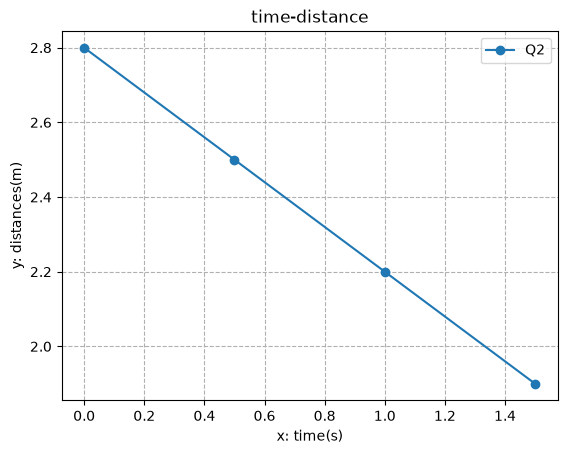

In [ ]:
# Q2 코드: 이 셀에서 빈칸과 주석 자리를 완성해요.
times_q2_s = [0.0, 0.5, 1.0, 1.5]  # 네 시각을 순서대로, 초
distances_q2_m = [2.8, 2.5, 2.2, 1.9]  # 같은 순서의 네 거리, m
fig2, ax2 = plt.subplots()  # Q2만의 새 그림
ax2.plot(times_q2_s, distances_q2_m, marker="o", label="Q2")
# 여기에 축 이름 두 줄, 제목, 눈금선, 범례 코드를 써요.
ax2.set_xlabel("x: time(s)")
ax2.set_ylabel("y: distances(m)")
ax2.set_title("time-distance")
ax2.grid(linestyle="--")
ax2.legend()

plt.show()

**Q2 답안**

- 마지막 점은 1.5초에 벽까지 1.9m 남았다는 뜻이에요.
- fig2는 전체영역이고, ax2는 그래프영역이에요.
- 동그라미가 보여주는 것: x와 y가 만나는 지점
- 선 이름표를 화면에 나타내는 코드 한 줄: legend


## 내 그리기 함수 만들기

### 점 목록을 두 목록으로 나눠요

`points`는 `(시각, 거리)`를 담은 목록이에요.
`for t_s, distance_m in points:`는 한 쌍을 꺼내 앞 값을 `t_s`, 뒤 값을 `distance_m`에 넣어요.
`append`는 목록의 맨 뒤에 값을 하나 붙여요. 아래 예제는 **실행만** 해요.


In [ ]:
example_points = [(0.0, 1.6), (0.5, 1.3), (1.0, 1.0)]  # (시각 초, 거리 m)
example_t = []  # 시각을 모을 빈 목록
example_d = []  # 같은 순서의 거리를 모을 빈 목록
for t_s, distance_m in example_points:
    example_t.append(t_s)  # 이번 점의 시각을 뒤에 붙여요
    example_d.append(distance_m)  # 바로 그 점의 거리를 뒤에 붙여요
print("시간:", example_t)
print("거리:", example_d)

시간: [0.0, 0.5, 1.0]
거리: [1.6, 1.3, 1.0]


### 확인 문제 Q3 다시 쓸 수 있는 함수 · 필수

**입력 자료:** Q2의 네 점과 아래 함수의 인자 세 개예요.

- `points`: `(시각 초, 거리 m)` 점 목록
- `line_name`: 선 이름 문자열
- `title_text`: 그래프 제목 문자열

**할 일:** 바로 아래 `Q3 함수 코드` 셀에서 `draw_distance`를 완성해요.

1. `append(...)` 두 곳을 채워 시간과 거리 목록을 만들어요.
2. `fig, ax = ...`에 새 그림을 만드는 호출을 넣고, 아래 주석 자리에 그리기 코드를 써요.
3. 시간 먼저, 거리 다음으로 그리고 `marker='o'`, `label=line_name`을 사용해요.
4. 축 이름과 단위, `title_text` 제목, 눈금선, 범례를 붙여요.
5. 마지막 `return fig, ax`는 그대로 둬요. 이 함수 안에는 `plt.show()`를 넣지 않아요.
6. 함수 셀을 실행한 뒤, 다음 `Q3 호출 코드` 셀은 수정 없이 실행해요.

`return fig, ax`는 만든 두 도구를 호출한 곳에 돌려줘요.
`fig3, ax3 = draw_distance(...)`는 그 도구를 새 이름으로 받아요.
이렇게 하면 다음 문제에서 같은 그림에 다른 선을 추가하거나 파일로 저장할 수 있어요.
`plt.show()`는 **함수 밖에서 마지막에** 한 번 실행해요.

**제출:** 완성된 함수 코드와 Q3 호출 결과 그래프 하나.


In [ ]:
# Q3 함수 코드: 이 함수의 주석 자리와 ...을 완성해요.
def draw_distance(points, line_name, title_text):
    times_s = []  # 각 점의 시각, 초
    distances_m = []  # 같은 점의 벽까지 거리, m
    for t_s, distance_m in points:
        times_s.append(t_s)
        distances_m.append(distance_m)
    fig3, ax3 = plt.subplots()  # 새 그림과 그릴 영역을 만드는 호출을 넣어요.
    # 여기에 선, 축 이름, 제목, 눈금선, 범례를 만드는 코드를 써요.
    ax3.plot(times_s, distances_m, marker="o", label=line_name)
    ax3.set_xlabel("x: times(s)")
    ax3.set_ylabel("y: distances(m)")
    ax3.set_title(title_text)
    ax3.grid()
    ax3.legend()

    return fig3, ax3  # 만든 그림과 그릴 영역을 호출한 곳에 돌려줘요

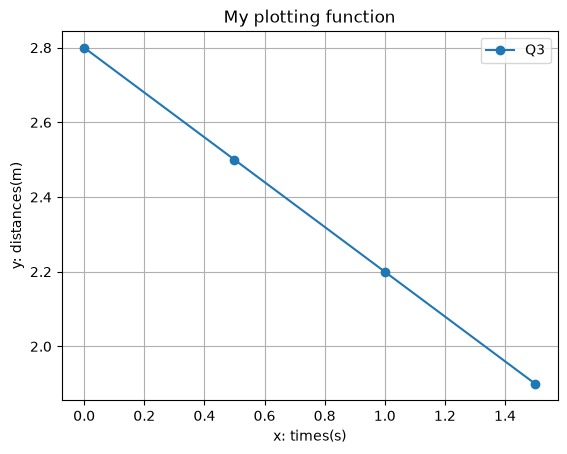

In [ ]:
# Q3 호출 코드: 수정하지 않고 실행해요.
practice_points = [(0.0, 2.8), (0.5, 2.5), (1.0, 2.2), (1.5, 1.9)]
fig3, ax3 = draw_distance(practice_points, "Q3", "My plotting function")
plt.show()

## 가상 로봇 두 대 비교하기

### 필요한 기존 함수는 여기 있어요

아래 제공 코드 셀은 **실행만** 해요. 다시 만들거나 Day19에서 복사하지 않아요.

- `dt_s`: 확인하고 움직이는 한 번의 간격, 초
- `wall_m`: 0m에서 시작하는 로봇 앞의 벽 위치, m. 처음 벽까지 남은 거리와 같아요.
- `stop_m`: 멈추기로 판단하는 거리 기준, m
- `cruise_mps`: GO일 때 1초 동안 가는 거리, m/s
- `t_s`, `x_m`, `front_m`: 이번 판단의 **이동 전** 시각, 로봇 위치, 벽까지 거리
- `next_t_s`, `next_x_m`, `next_front_m`: 이번 판단 뒤의 **이동 후** 값

현재 거리 `front_m`이 기준 이하이면 STOP이에요.
그보다 멀면 GO로 정하고 `dt_s`초 동안 움직인 뒤 다시 확인해요. 움직이는 중간에는 새 판단을 하지 않아요.
STOP에서는 위치와 이동 후 시각을 그대로 두고 기록을 끝내요.
`make_points`는 시작점과 GO의 이동 후 점만 모아 STOP의 같은 점을 중복으로 붙이지 않아요.

Day19 기본값인 벽 2.0m, STOP 기준 0.75m, 속도 0.5m/s를 유지했어요.
오늘 문제에서는 함수 인자로 바꿀 값을 명시해요. `round(값, 6)`은 소수 계산의 긴 꼬리를 줄이는 제공 코드예요.


In [ ]:
# 제공 함수: 수정하지 말고 한 번 실행해요.
def run_sim(dt_s, wall_m=2.0, stop_m=0.75, cruise_mps=0.5):
    x_m = 0.0  # 로봇의 시작 위치, m
    rows = []  # 판단과 이동 전후 값을 모을 목록
    for step in range(20):  # 최대 20번 확인하며, 첫 STOP에서 끝나요
        t_s = round(step * dt_s, 6)  # 이번 판단의 이동 전 시각, 초
        front_m = round(wall_m - x_m, 6)  # 이동 전 벽까지 거리, m
        action = "STOP" if front_m <= stop_m else "GO"
        speed_mps = 0.0 if action == "STOP" else cruise_mps
        next_x_m = round(x_m + speed_mps * dt_s, 6)  # 이동 후 위치, m
        next_front_m = round(wall_m - next_x_m, 6)  # 이동 후 벽까지 거리, m
        next_t_s = t_s if action == "STOP" else round(t_s + dt_s, 6)
        rows.append(
            {
                "t_s": t_s,
                "x_m": x_m,
                "front_m": front_m,
                "action": action,
                "speed_mps": speed_mps,
                "next_t_s": next_t_s,
                "next_x_m": next_x_m,
                "next_front_m": next_front_m,
            }
        )
        x_m = next_x_m  # 이번 이동 후 위치를 다음 판단의 이동 전 위치로 써요
        if action == "STOP":
            break
    return rows


def make_points(rows):
    # 첫 판단의 이동 전 시각과 그때 거리를 시작점으로 넣어요.
    points = [(rows[0]["t_s"], rows[0]["front_m"])]
    for row in rows:
        if row["action"] == "GO":
            # 같은 행의 이동 후 시각과 이동 후 거리를 한 점으로 묶어요.
            points.append((row["next_t_s"], row["next_front_m"]))
    return points

### 같은 시각에 있는 두 점을 비교해요

![E와 F의 시간과 거리 그래프에서 같은 1초의 두 점 비교](assets/03-same-time-comparison.png)

위 그림의 가로축 x는 시간(초), 세로축 y는 벽까지 남은 거리(m)예요.
예시 E와 F는 1초라는 **같은 가로 위치**에서 각각 1.6m, 1.2m예요.
이때 F가 벽에 0.4m 더 가까워요. 높이가 낮을수록 남은 거리가 작기 때문이에요.
이 숫자는 설명용이며 아래 A와 B의 답이 아니에요.

한 그림에 두 선을 그리려면 **같은 ax에** `plot`을 한 번 더 해요.
두 번째 선을 추가한 뒤 `legend()`도 다시 실행해야 두 이름이 모두 보여요.
`marker='s'`는 네모 표시예요.

### 확인 문제 Q4 시작 거리가 다른 두 로봇 · 필수

**입력 조건:** A와 B는 모두 0초, 로봇 위치 0m에서 시작해요.

- A: 처음 벽까지 거리 2.6m
- B: 처음 벽까지 거리 2.0m
- 공통: `dt_s=0.5`초, `stop_m=0.7`m, `cruise_mps=0.5`m/s

기본값에서 STOP 기준은 0.75m → 0.7m로 바꿔요.
A와 B 사이에서 바꾸는 조건은 **벽까지 시작 거리 하나**예요.

**할 일**

1. 아래 `Q4 실행 코드`에서 A와 B의 `wall_m=...` 두 곳을 채워요.
2. B의 각 점에서 시간과 거리를 모으도록 `append(...)` 두 곳을 채워요.
3. `ax_compare.plot`의 두 빈칸에 B의 시간 목록과 거리 목록을 넣어요.
4. 셀을 실행해 A와 B가 함께 있는 그래프와 점 목록을 확인해요.
5. 두 기록에 모두 있는 **1.5초**의 거리와 차이를 `Q4 답안` Markdown 셀에 적어요.

**제출:** 완성 코드, 두 선이 있는 그래프 하나, 수치와 비교 기준을 쓴 답안.


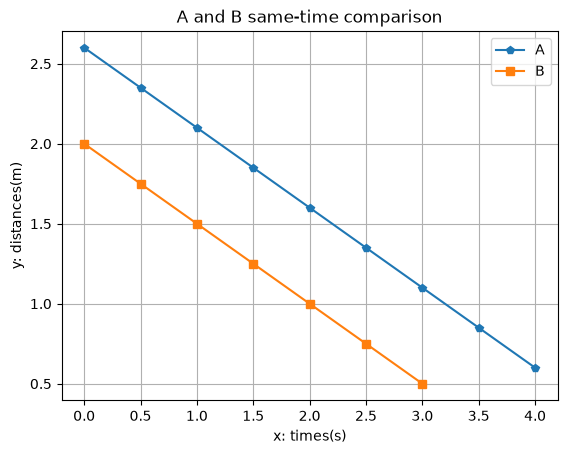

A 점: [(0.0, 2.6), (0.5, 2.35), (1.0, 2.1), (1.5, 1.85), (2.0, 1.6), (2.5, 1.35), (3.0, 1.1), (3.5, 0.85), (4.0, 0.6)]
B 점: [(0.0, 2.0), (0.5, 1.75), (1.0, 1.5), (1.5, 1.25), (2.0, 1.0), (2.5, 0.75), (3.0, 0.5)]


In [ ]:
# Q4 실행 코드
rows_a = run_sim(dt_s=0.5, wall_m=2.6, stop_m=0.7, cruise_mps=0.5)
rows_b = run_sim(dt_s=0.5, wall_m=2.0, stop_m=0.7, cruise_mps=0.5)
points_a = make_points(rows_a)  # A의 (시각 초, 거리 m) 점 목록
points_b = make_points(rows_b)  # B의 (시각 초, 거리 m) 점 목록

fig_compare, ax_compare = draw_distance(points_a, "A", "A and B same-time comparison")
times_b_s = []  # B의 시각, 초
distances_b_m = []  # B의 같은 시각 거리, m
for t_s, distance_m in points_b:
    times_b_s.append(t_s)
    distances_b_m.append(distance_m)
ax_compare.plot(
    times_b_s, distances_b_m, marker="s", label="B"
)  # 같은 그릴 영역에 B를 추가해요
ax_compare.legend()  # 두 선의 이름표를 새로 보여줘요
plt.show()
print("A 점:", points_a)
print("B 점:", points_b)

**Q4 답안**

- 1.5초의 거리: A 1.85m, B 1.25m
- 이때 벽에 더 가까운 로봇: B
- 두 거리의 차이: 0.60m
- 같은 시각을 골라 비교하는 이유: 같은 시간에 거리를 비교하기 위해서
- 두 선의 점 모양과 범례 이름이 서로 맞는지 확인: 확인


## 확인 간격 바꾸기

### 확인 문제 Q5 멈추는 순간도 같을까요 · 필수

**입력 조건:** Q4의 A는 그대로 두고 D를 만들어요.
D는 A의 확인 간격만 **0.5초 → 0.75초**로 바꿔요.
시작 거리 2.6m, STOP 기준 0.7m, GO 속도 0.5m/s는 같아요.

**먼저 할 일:** 코드를 실행하기 전에 바로 아래 `Q5 예상` Markdown 셀을 써요.
첫 STOP 시각이 같을지 다를지 예상하고 이유를 한 문장 적어요. 틀려도 고치지 않고 남겨요.


**Q5 예상 · 실행 전**

- 예상: 첫 STOP 시각이 같을 것이다 / 다를 것이다 중 같다
- 이렇게 예상한 이유: 체크하는 간격만 짧아졌을뿐


**실행할 일:** 아래 `Q5 실행 코드`의 `dt_s=...`만 채워요. 나머지는 제공 코드예요.
Q3의 함수를 다시 사용해 A와 D를 새 그림에 함께 그려요.
`rows_a[-1]`은 A의 마지막 행이에요. 이 입력 조건에서는 첫 STOP에서 반복을 끝내므로 마지막 행이 첫 STOP 기록이에요.
출력의 `action`이 STOP인지 확인하고 결과를 읽어요.

**답할 곳:** 코드 실행 후 바로 아래 `Q5 결과` Markdown 셀.
공통 시각 **1.5초**의 두 거리와 각각 첫 STOP 시각·거리를 써요.
두 STOP 점을 같은 시각 비교라고 해도 되는지, 확인 간격이 결과에 어떤 영향을 주었는지 설명해요.

**제출:** 예상, 실행 코드와 그래프, 결과 답안.


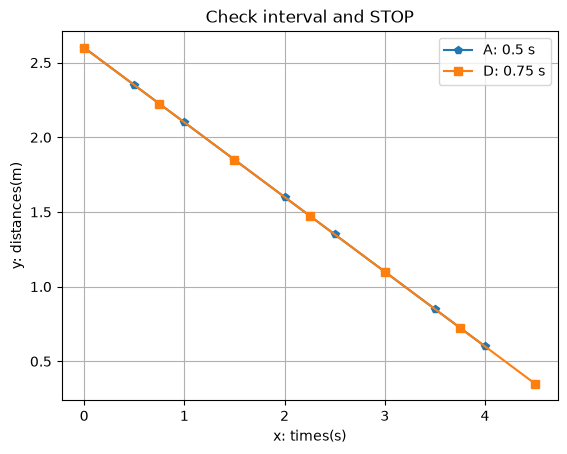

A 점: [(0.0, 2.6), (0.5, 2.35), (1.0, 2.1), (1.5, 1.85), (2.0, 1.6), (2.5, 1.35), (3.0, 1.1), (3.5, 0.85), (4.0, 0.6)]
D 점: [(0.0, 2.6), (0.75, 2.225), (1.5, 1.85), (2.25, 1.475), (3.0, 1.1), (3.75, 0.725), (4.5, 0.35)]
A 마지막 행: {'t_s': 4.0, 'x_m': 2.0, 'front_m': 0.6, 'action': 'STOP', 'speed_mps': 0.0, 'next_t_s': 4.0, 'next_x_m': 2.0, 'next_front_m': 0.6}
D 마지막 행: {'t_s': 4.5, 'x_m': 2.25, 'front_m': 0.35, 'action': 'STOP', 'speed_mps': 0.0, 'next_t_s': 4.5, 'next_x_m': 2.25, 'next_front_m': 0.35}


In [ ]:
# Q5 실행 코드: dt_s=... 한 곳만 채워요.
rows_d = run_sim(dt_s=0.75, wall_m=2.6, stop_m=0.7, cruise_mps=0.5)
points_d = make_points(rows_d)
fig_dt, ax_dt = draw_distance(points_a, "A: 0.5 s", "Check interval and STOP")
times_d_s = []  # D의 기록 시각, 초
distances_d_m = []  # 그 시각의 벽까지 거리, m
for t_s, distance_m in points_d:
    times_d_s.append(t_s)
    distances_d_m.append(distance_m)
ax_dt.plot(times_d_s, distances_d_m, marker="s", label="D: 0.75 s")
ax_dt.legend()
plt.show()
print("A 점:", points_a)
print("D 점:", points_d)
print("A 마지막 행:", rows_a[-1])
print("D 마지막 행:", rows_d[-1])

**Q5 결과 · 실행 후**

- 공통 1.5초의 거리: A 1.85m, D 1.85m
- A 마지막 action: STOP / 첫 STOP: 4.0초, 0.6m
- D 마지막 action: STOP / 첫 STOP: 4.5초, 0.35m
- 두 STOP 점이 같은 시각 비교인가요? 아니오 / 근거: 출력결과
- 예상과 같았나요? 아니오
- 속도와 시작 거리가 같아도 확인 간격이 영향을 주는 이유: 확인간격이 조건문을 넘어가는 경우가 있어서


## 그래프가 나와도 뜻이 틀릴 수 있어요

### 확인 문제 Q6 시간과 거리가 뒤바뀐 그래프 고치기 · 필수

**입력 자료:** `(0초, 2.5m)`, `(1초, 1.6m)`, `(2초, 0.7m)`예요.
아래 코드는 오류 메시지 없이 그림이 나와도, 자료가 말하는 시간과 거리 그래프는 아니에요.

**할 일**

1. 아래 `Q6 코드`를 **수정하기 전에 한 번** 실행해요.
2. 첫 점의 가로 눈금 값과 세로 눈금 값을 읽어 아래 답안의 `수정 전`에 적어요.
3. **`ax_bug.plot(...)` 한 줄의 첫째·둘째 인자만** 고쳐요.
   입력 목록의 숫자, 축 이름, 제목은 바꾸지 않아요.
4. 같은 셀을 다시 실행해 새 그림을 만들고 `수정 후`와 이유를 적어요.

**제출:** 고친 코드와 마지막 그래프, 수정 전·후 좌표를 쓴 `Q6 답안` Markdown 셀.
수정 전 그림을 따로 저장할 필요는 없어요.


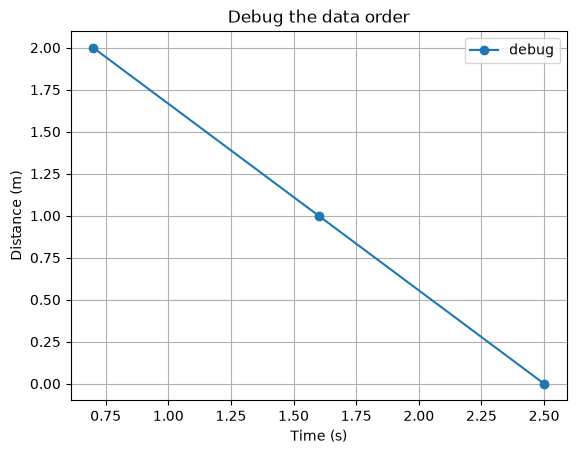

In [ ]:
# Q6 코드: 먼저 그대로 실행한 뒤 plot 한 줄의 두 인자만 고쳐요. => 축변경
debug_times_s = [0.0, 1.0, 2.0]  # 실제 자료의 시각, 초
debug_distances_m = [2.5, 1.6, 0.7]  # 같은 시각의 벽까지 거리, m
fig_bug, ax_bug = plt.subplots()  # 실행할 때마다 별도의 새 그림
ax_bug.plot(debug_times_s, debug_distances_m, marker="o", label="debug")
ax_bug.set_xlabel("Time (s)")
ax_bug.set_ylabel("Distance (m)")
ax_bug.set_title("Debug the data order")
ax_bug.grid(True)
ax_bug.legend()
plt.show()

**Q6 답안**

- 수정 전 첫 왼쪽 점의 눈금: 가로 0.7, 세로 0.00
- 수정 후 첫 점: (0.00초, 2.50m)
- 바꾼 두 인자의 순서: m,s → s,m
- 오류 메시지가 없는데도 잘못된 그래프였던 이유: 축이 바뀌어있었음


## 내 말로 그래프 설명하기

### 확인 문제 Q7 친구의 설명을 확인해요 · 필수

**볼 자료:** Q4에서 내가 만든 A와 B 그래프, 그리고 1.5초 비교 결과예요.
친구가 다음처럼 말했어요.

- “두 선이 모두 아래로 향하니까 로봇은 실제 공간에서 아래쪽으로 내려갔어.”
- “점과 점 사이에 그어진 선의 모든 위치도 센서로 직접 측정한 값이야.”

**할 일:** 코드를 수정하지 말고 아래 `Q7 답안` Markdown 셀에 3~4문장을 써요.

1. 1.5초에 어느 로봇이 벽에 더 가까운지, 내 수치 두 개를 근거로 설명해요.
2. 선이 아래로 향한다는 것이 **벽까지 남은 거리**에 대해 무엇을 뜻하는지 써요.
3. 친구의 두 설명에서 바로잡을 내용을 쓰고, 여기 자료가 시뮬레이션이라는 점도 밝혀요.

모르는 부분은 추측으로 채우기보다 질문으로 남겨도 돼요.


**Q7 답안**

- 내 설명 3~4문장: : A는 1.85m, B는 1.25m. A,D는 같고 B는 벽에 더 가까워. 그리고 선이 아래로 향한다는것은 벽까지 남은거리와 가까와 진다고 생각하면돼. 로봇이 아래로 내려가는게 아니야. 그리고 점과 점 사이의 그저니 선의 모든 위치는 센서로 직접 측정하지않고 marker로 찍혀진 부분만 시뮬레이션으로 만든 기록이야
- 막힌 부분 한 가지 또는 `없음`: \_\_\_
- 자기 평가 하나 선택: 혼자 설명할 수 있음 / 교재를 보면 설명할 수 있음 / 같이 다시 보고 싶음


## 결과 저장하기

### 그림을 파일로 남기는 방법

`fig.savefig(파일_경로)`는 그 `fig`의 그림을 파일로 저장해요.
마지막에 화면에 나온 그림을 고르는 대신 **Q4의 그림**인 `fig_compare`를 지정해야 A와 B 비교 그림을 저장해요.
아래 저장 도우미는 새 결과 폴더를 만들고, 그 안에 PNG 그림과 TXT 설명을 함께 저장해요.
이미 같은 이름의 폴더가 있으면 번호를 올려 새 폴더를 만들기 때문에 이전 결과를 덮어쓰지 않아요.

**제공 코드:** 바로 아래 셀은 수정하지 말고 실행만 해요. 저장 도우미의 문법을 외우는 것은 오늘 과제가 아니에요.
이 셀은 함수를 준비할 뿐, 아직 파일을 저장하지 않아요.


In [ ]:
from pathlib import Path  # 파일과 폴더의 경로를 다루는 도구


def save_new_result(figure, explanation):
    root = Path("results")  # 노트북의 현재 작업 폴더 안에 결과를 보관해요
    if root.is_symlink():
        raise ValueError(
            "results가 다른 곳을 가리키는 링크예요. 저장하지 않고 확인해요."
        )
    root.mkdir(exist_ok=True)
    number = 1
    while True:
        folder = root / f"day20-{number:03d}"  # 001, 002처럼 새 번호를 붙여요
        try:
            folder.mkdir()  # 이미 있으면 덮어쓰지 않고 다음 번호로 넘어가요
            break
        except FileExistsError:
            number += 1
    image_path = folder / "comparison.png"
    text_path = folder / "explanation.txt"
    # x 모드는 같은 이름의 파일이 있으면 덮어쓰지 않는 저장 방식이에요.
    with image_path.open("xb") as image_file:
        figure.savefig(image_file, format="png", dpi=160, bbox_inches="tight")
    with text_path.open("x", encoding="utf-8") as text_file:
        text_file.write(explanation.strip() + "\n")
    print("저장한 그림:", image_path)
    print("저장한 설명:", text_path)
    return image_path, text_path

### 확인 문제 Q8 내 결과 저장하고 제출하기 · 필수

**저장할 자료:** Q4의 `fig_compare` 그림과 내가 Q7에 쓴 설명이에요.

**할 일**

1. 아래 `Q8 저장 코드`의 따옴표 세 개 안에 Q7의 내 설명을 복사해 넣어요.
2. 같은 셀에서 `save_new_result(...)`의 첫째 인자만 채워요. 저장할 그림의 변수 이름을 써요.
3. 실행 후 출력된 폴더를 열어 `comparison.png`와 `explanation.txt`를 각각 확인해요.
4. PNG가 A/B 비교 그림인지, TXT가 내 설명인지 확인하고 아래 Markdown에 기록해요.

**제출할 곳:** 이 노트북의 Q1~Q8 답안과 실행 결과, 그리고 새 결과 폴더의 파일 두 개예요.
채팅에 코드를 전부 다시 붙일 필요는 없어요.


In [ ]:
# Q8 저장 코드: 내 설명과 저장할 그림 이름을 채운 뒤 실행해요.
summary_text = """
A는 1.85m, B는 1.25m. A,D는 같고 B는 벽에 더 가까워. 그리고 선이 아래로 향한다는것은 벽까지 남은거리와 가까와 진다고 생각하면돼. 로봇이 아래로 내려가는게 아니야. 그리고 점과 점 사이의 그저니 선의 모든 위치는 센서로 직접 측정하지않고 marker로 찍혀진 부분만 시뮬레이션으로 만든 기록이야
"""
saved_image, saved_text = save_new_result(fig_compare, summary_text)

저장한 그림: results\day20-003\comparison.png
저장한 설명: results\day20-003\explanation.txt


**Q8 답안**

- 저장된 결과 폴더 이름: result/day20-001
- PNG가 A와 B 비교 그림인지 직접 열어 확인: 봤어
- TXT가 내가 쓴 설명인지 직접 열어 확인: 봤어

**마무리 확인**

- Q1~Q8의 코드와 Markdown 답안을 작성했어요.
- 그래프에 제목, 시간과 거리 단위, 점 표시, 범례가 보이는지 확인했어요.
- 결과 파일 두 개를 열어 확인했어요.
- 타이머를 썼다면 맨 아래 종료 셀을 실행하고 `종료`를 입력해요.
- 그다음 Ctrl+S로 노트북을 저장해요.
- 이 대화에 `다 풀었어`라고 알려줘요. 걸린 시간과 막힌 곳도 짧게 덧붙여 줘요.

다 못 풀었으면 마지막으로 한 문제와 막힌 곳을 알려줘도 괜찮아요.


## 선택 활동

필수 Q1~Q8을 마쳤으면 하지 않아도 완료예요. 약 5분이 더 필요해요.

**볼 자료:** Q4에서 만든 두 선의 점 모양이에요.
바로 아래 선택 코드 셀에 Q4의 `fig_compare, ax_compare = draw_distance(...)` 줄부터
`plt.show()` 줄까지 복사하고, B의 `marker='s'`만 `marker='^'`로 바꿔요.
`'^'`는 세모 표시예요. A와 B의 데이터 숫자는 바꾸지 않아요.
실행한 뒤 아래 선택 답안에 모양만 달라졌는지, 거리 수치도 달라졌는지 써요.


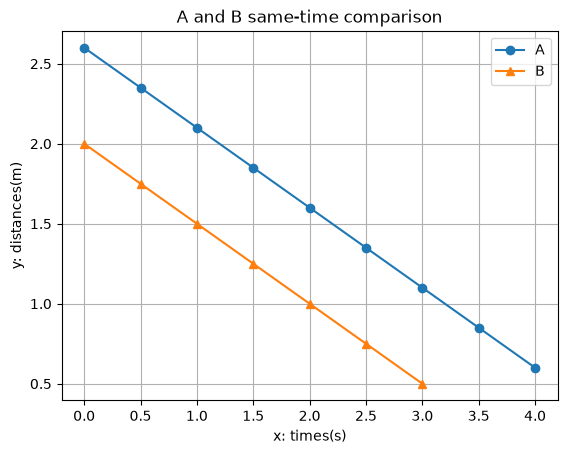

A 점: [(0.0, 2.6), (0.5, 2.35), (1.0, 2.1), (1.5, 1.85), (2.0, 1.6), (2.5, 1.35), (3.0, 1.1), (3.5, 0.85), (4.0, 0.6)]
B 점: [(0.0, 2.0), (0.5, 1.75), (1.0, 1.5), (1.5, 1.25), (2.0, 1.0), (2.5, 0.75), (3.0, 0.5)]


In [42]:
# 선택 활동 코드: Q4의 완성된 그리기 부분을 복사해 B marker만 바꿔요.
# Q4 실행 코드
rows_a = run_sim(dt_s=0.5, wall_m=2.6, stop_m=0.7, cruise_mps=0.5)
rows_b = run_sim(dt_s=0.5, wall_m=2.0, stop_m=0.7, cruise_mps=0.5)
points_a = make_points(rows_a)  # A의 (시각 초, 거리 m) 점 목록
points_b = make_points(rows_b)  # B의 (시각 초, 거리 m) 점 목록

fig_compare, ax_compare = draw_distance(points_a, "A", "A and B same-time comparison")
times_b_s = []  # B의 시각, 초
distances_b_m = []  # B의 같은 시각 거리, m
for t_s, distance_m in points_b:
    times_b_s.append(t_s)
    distances_b_m.append(distance_m)
ax_compare.plot(
    times_b_s, distances_b_m, marker="^", label="B"
)  # 같은 그릴 영역에 B를 추가해요
ax_compare.legend()  # 두 선의 이름표를 새로 보여줘요
plt.show()
print("A 점:", points_a)
print("B 점:", points_b)

**선택 활동 답안**

- 바뀐 표시와 그대로인 것: B마커만 바뀜


## 선택 새로 측정하기

다시 측정하고 싶을 때만 아래 셀의 `enabled = False`를 `True`로 바꾸고 실행한 뒤 `초기화`를 입력해요.
이전 기록을 백업한 다음 맨 위 시작 셀을 다시 실행해요.
보통 학습과 `모두 실행`만으로는 초기화되지 않아요.


In [ ]:
# 이 셀은 커널을 다시 시작한 뒤에도 독립적으로 작동해요.
from pathlib import Path

_cwd = Path.cwd()
_dirs = [
    p
    for p in (_cwd, _cwd / "day20-matplotlib-time-distance")
    if p.name == "day20-matplotlib-time-distance"
    and p.is_dir()
    and (p / "day20.ipynb").is_file()
    and (p / "study_timer.py").is_file()
]
if (
    len(_dirs) != 1
    or _dirs[0].is_symlink()
    or (_dirs[0] / "day20.ipynb").is_symlink()
    or (_dirs[0] / "study_timer.py").is_symlink()
):
    print("교재 폴더를 하나로 확인할 수 없어요. Day20 폴더에서 노트북을 열어 주세요.")
else:
    # 검증한 파일을 메모리에서 읽고 실행해요. 임포트 캐시는 만들지 않아요.
    _helper = _dirs[0] / "study_timer.py"
    _timer = {"__name__": "day20_timer"}
    try:
        exec(compile(_helper.read_bytes(), str(_helper), "exec"), _timer)
    except (OSError, SyntaxError):
        print("타이머 도구를 읽을 수 없어요. 기록을 바꾸지 않고 함께 확인해 주세요.")
    else:
        enabled = False  # 다시 측정할 때만 True로 바꾸세요
        if enabled:
            _timer["action"]("reset", input("초기화하려면 초기화 입력: "), enabled=True)
        else:
            print("초기화는 비활성화되어 있어요.")

기존 기록을 백업했어요. 새 측정은 맨 위 시작 셀을 다시 실행해 주세요.


## 선택 학습 종료

타이머를 썼다면 완료할 때 아래 셀을 실행하고 직접 `종료`를 입력해요. 빈 입력은 취소예요.
`모두 실행` 중에는 `종료`를 입력하지 마세요.
**종료 셀에서 확인한 시각**이 학습 종료 시각이며, 실제 저장·메시지 시각과는 별개예요.
그다음 Ctrl+S로 노트북을 저장하고, 이 대화에 `다 풀었어`라고 알려줘요.


In [ ]:
# 이 셀은 커널을 다시 시작한 뒤에도 독립적으로 작동해요.
from pathlib import Path

_cwd = Path.cwd()
_dirs = [
    p
    for p in (_cwd, _cwd / "day20-matplotlib-time-distance")
    if p.name == "day20-matplotlib-time-distance"
    and p.is_dir()
    and (p / "day20.ipynb").is_file()
    and (p / "study_timer.py").is_file()
]
if (
    len(_dirs) != 1
    or _dirs[0].is_symlink()
    or (_dirs[0] / "day20.ipynb").is_symlink()
    or (_dirs[0] / "study_timer.py").is_symlink()
):
    print("교재 폴더를 하나로 확인할 수 없어요. Day20 폴더에서 노트북을 열어 주세요.")
else:
    # 검증한 파일을 메모리에서 읽고 실행해요. 임포트 캐시는 만들지 않아요.
    _helper = _dirs[0] / "study_timer.py"
    _timer = {"__name__": "day20_timer"}
    try:
        exec(compile(_helper.read_bytes(), str(_helper), "exec"), _timer)
    except (OSError, SyntaxError):
        print("타이머 도구를 읽을 수 없어요. 기록을 바꾸지 않고 함께 확인해 주세요.")
    else:
        _timer["finish_interactive"]()